# UV-Decomposition Recommendation System  🚀

Data Mining Final Project

Angel Coronel

Data Mining - CSC 84040

Spring 2025

---


## 0 Environment & Packages

In [ ]:
# packages
!pip install -q lightfm scikit-learn pandas matplotlib

In [ ]:
# https://grouplens.org/datasets/movielens/
# download MovieLens 100K dataset (movie ratings)
!wget -q https://files.grouplens.org/datasets/movielens/ml-100k.zip
!unzip -o ml-100k.zip

Archive:  ml-100k.zip
  inflating: ml-100k/allbut.pl       
  inflating: ml-100k/mku.sh          
  inflating: ml-100k/README          
  inflating: ml-100k/u.data          
  inflating: ml-100k/u.genre         
  inflating: ml-100k/u.info          
  inflating: ml-100k/u.item          
  inflating: ml-100k/u.occupation    
  inflating: ml-100k/u.user          
  inflating: ml-100k/u1.base         
  inflating: ml-100k/u1.test         
  inflating: ml-100k/u2.base         
  inflating: ml-100k/u2.test         
  inflating: ml-100k/u3.base         
  inflating: ml-100k/u3.test         
  inflating: ml-100k/u4.base         
  inflating: ml-100k/u4.test         
  inflating: ml-100k/u5.base         
  inflating: ml-100k/u5.test         
  inflating: ml-100k/ua.base         
  inflating: ml-100k/ua.test         
  inflating: ml-100k/ub.base         
  inflating: ml-100k/ub.test         


In [ ]:
# import libraries
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.manifold import TSNE
from tqdm.auto import tqdm
from scipy.sparse import lil_matrix
from lightfm import LightFM
from lightfm.data import Dataset
from lightfm.evaluation import precision_at_k, recall_at_k
from lightfm.cross_validation import random_train_test_split


## 1 Load MovieLens 100K

Start by loading user–item ratings and keeping only strong positive ratings (4 and 5)

- this simplifies the task to implicit feedback (meaning likes only)

Load movie titles to recommendations to interpret later

In [ ]:
# load ratings
ratings = pd.read_csv("ml-100k/u.data", sep="\t", names=["user", "item", "rating", "timestamp"])
# keep only strong positive ratings
ratings = ratings[ratings["rating"] >= 4]  # 4 or 5 stars

print("rating data:")
print(ratings.head(10))

# users and items dataset
dataset = Dataset()
users = (x for x in ratings['user'])
items = (x for x in ratings['item'])
dataset.fit(users, items)

# build a users × items matrix from the ratings
userItemPairs = []

for _, row in ratings.iterrows():
  userItemPairs.append((row['user'], row['item']))

interactions, weights = dataset.build_interactions(userItemPairs)

rating data:
    user  item  rating  timestamp
5    298   474       4  884182806
7    253   465       5  891628467
11   286  1014       5  879781125
12   200   222       5  876042340
16   122   387       5  879270459
18   291  1042       4  874834944
20   119   392       4  886176814
21   167   486       4  892738452
22   299   144       4  877881320
24   308     1       4  887736532


In [ ]:
# load movie metadata: item ID, title, and more (we only need the first two columns)
movies = pd.read_csv("ml-100k/u.item", sep="|", header=None, encoding="latin-1", usecols=[0, 1])
movies.columns = ["item_id", "title"]

print(movies.head())

   item_id              title
0        1   Toy Story (1995)
1        2   GoldenEye (1995)
2        3  Four Rooms (1995)
3        4  Get Shorty (1995)
4        5     Copycat (1995)


## 2 Exploratory Data Analysis

Visualize ratings distribution and measure how scarce the data is



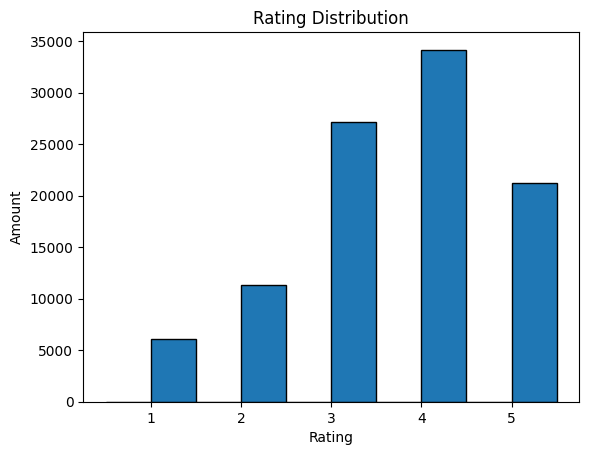

scarcity of >=4 feedback matrix: 4.0625%


In [ ]:
# histogram of all ratings before filtering
allRatings = pd.read_csv("ml-100k/u.data", sep="\t", names=["user", "item", "rating", "timestamp"])

plt.hist(allRatings["rating"], bins=np.arange(0.5, 5.6, 0.5), edgecolor="k")
plt.xlabel("Rating"); plt.ylabel("Amount"); plt.title("Rating Distribution")
plt.show()

# calculate matrix scarcity after filtering
nUsers = ratings["user"].nunique()
nItems = ratings["item"].nunique()
scarcity = 100 * len(ratings) / (nUsers * nItems)
print(f"scarcity of >=4 feedback matrix: {scarcity:.4f}%")


## 3 Train/Test Split for Implicit Interactions

split the interaction matrix into train and test parts

In [ ]:
# random split into 80/20 train/test
trainInter, testInter = random_train_test_split(
  interactions, test_percentage=0.2, random_state=np.random.RandomState(42)
)

print("Train interactions:", trainInter.nnz)
print("Test interactions:", testInter.nnz)


Train interactions: 44300
Test interactions: 11075


## 4 Baseline - Item Popularity (MostPopular recommender)

A simple baseline: recommend the most popular items to everyone



In [ ]:
# count how many times each item was interacted with
itemPopularity = np.array(trainInter.sum(axis=0)).ravel()

# precision using the top-k most popular items
def popularityPrecision(test, k=10):
  # top‑k popular indices
  topKItems = np.argsort(-itemPopularity)[:k]
  correct = 0

  # for each user, count how many of those appear in its held‑out positives
  for u in range(test.shape[0]):
    # items with 1s for this user
    positives = test.rows[u]
    correct += len(set(topKItems) & set(positives))

  # equals micro averaged precision
  return correct / test.nnz

# convert to LIL for row-wise access
testInterLil = testInter.tolil()
popPrec = popularityPrecision(testInterLil, k=10)

print(f"Popularity Precision for top 10 items = {popPrec:.3f}")


Popularity Precision for top 10 items = 0.062


## 5 LightFM Model - WARP Loss (UV Decomposition)

Train a real recommendation model using LightFM with WARP loss.
This learns user and item embeddings (UV-decomposition) that predict preferences.


In [ ]:
model = LightFM(no_components=20, loss="warp", random_state=42, learning_rate=0.05, item_alpha=1e-6, user_alpha=1e-6)
# no_components is the size of U and V
# WARP loss is the ranking

print("Training the model")
start = time.time()
model.fit(trainInter, epochs=30, num_threads=4, verbose=True)
end = time.time()

print(f"\ntraining took {end - start:.2f}")

Training the model


Epoch: 100%|██████████| 30/30 [00:03<00:00,  8.45it/s]


training took 3.56


## 6 Evaluation - Precision and Recall with top k items ranked

Evaluate how well the model recommends good items to users.


In [ ]:
k = 10
prec = precision_at_k(model, testInter, trainInter, k=k, num_threads=4).mean()
rec  = recall_at_k(model, testInter, trainInter, k=k, num_threads=4).mean()
print(f"LightFM (WARP) Precision at k = {k} = {prec:.3f}")
print(f"LightFM (WARP) Recall at k = {k} = {rec:.3f}")

LightFM (WARP) Precision at k = 10 = 0.207
LightFM (WARP) Recall at k = 10 = 0.224


## 7 Cold start analysis

Evaluate how well the recommendation system performs on users with very few known interactions. Mask users with < 10 positives and recompute metrics.

In [ ]:
#  per-user precision with user IDs retained
def precisionDictAtK(model, test_interactions, train_interactions, k=10):
  precArray = precision_at_k(model, test_interactions, train_interactions, k=k, num_threads=4)

  # only users with >=1 test interaction are included in precArray
  testNNZ = test_interactions.getnnz(axis=1)
  validUserIDs = np.where(testNNZ > 0)[0]

  # {user_id: precision} for users with test data
  precisionDict = {}
  for i, uid in enumerate(validUserIDs):
    precisionDict[uid] = precArray[i]
  return precisionDict


# build precision dictionary
precisionDict = precisionDictAtK(model, testInter, trainInter, k=10)

# identify cold start users (low train interactions + some test interactions)
trainUserCounts = np.array(trainInter.sum(axis=1)).ravel()
testUserCounts  = np.array(testInter.sum(axis=1)).ravel()
coldUserIDs = np.where((trainUserCounts < 10) & (testUserCounts > 0))[0]
print(f"Cold start users with <10 train interactions and >0 test interactions: {len(coldUserIDs)}")

# compute cold start precision only for users with valid test data
coldPrecisions = []
for userID in coldUserIDs:
    if userID in precisionDict:
        value = precisionDict[userID]
        coldPrecisions.append(value)
coldPrecision = np.mean(coldPrecisions)

# compute full precision across all users with test data
fullPrecision = np.mean(list(precisionDict.values()))

print(f"Full Precision top 10 = {fullPrecision:.3f}")
print(f"Cold start Precision top 10 = {coldPrecision:.3f}")

Cold start users with <10 train interactions and >0 test interactions: 84
Full Precision top 10 = 0.207
Cold start Precision top 10 = 0.080


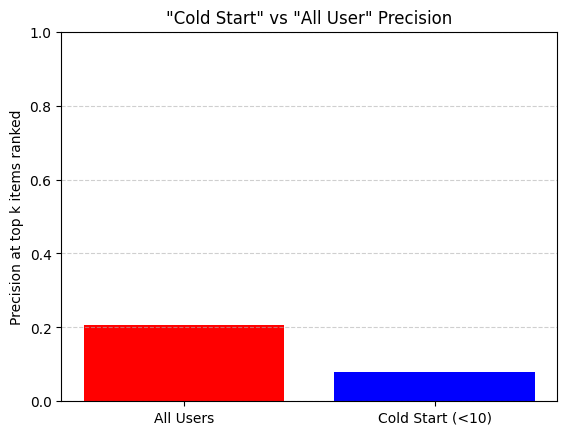

In [ ]:
plt.bar(["All Users", "Cold Start (<10)"], [fullPrecision, coldPrecision], color=["red", "blue"])
plt.ylabel("Precision at top k items ranked")
plt.title("\"Cold Start\" vs \"All User\" Precision")
plt.ylim(0, 1)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

## 8 Top-N Recommendations - Example User


pick one user and generate 5 recommendations they haven’t seen yet


In [ ]:
def recommend(model, userID, trainMat, N=5):
  # items already liked by the user (exclude)
  knownPositives = trainMat.rows[userID]
  scores = model.predict(userID, np.arange(trainMat.shape[1]), num_threads=4)
  top_items = np.argsort(-scores)[:N + len(knownPositives)]
  # filter out already‑seen
  recs = []
  for item in top_items:
    if item not in knownPositives:
      recs.append(item)
      # recs contains up to N recommendations
      if len(recs) == N:
        break
  return recs

# pick a user
userID   = 37 # raw ID in the data

userIDMap, userFeatureMap, itemIDMap, itemFeatureMap = dataset.mapping()
userIDIdx = userIDMap[userID] # internal index

# map internal item IDs back to original MovieLens item IDs
reverseItemIDMap = {v: k for k, v in itemIDMap.items()}

# convert training set to LIL for access
trainInterLIL = trainInter.tolil()

# known liked items
likedItems = trainInterLIL.rows[userIDIdx]
likedItemsRaw = [reverseItemIDMap[i] for i in likedItems]

N = 5

# map to liked titles
likedMask   = movies["item_id"].isin(likedItemsRaw)
likedSubset = movies.loc[likedMask, "title"]
likedTitles  = likedSubset.tolist()
print(f"User {userID} has previously liked: {likedItemsRaw[:N]}")
print("Titles")
for title in likedTitles[:N]:
  print("\t", title)

# get  recommendations
recsIdx = recommend(model, userIDIdx, trainInterLIL, N)
recsRaw = [reverseItemIDMap[i] for i in recsIdx]

print(f"\nTop {N} new movies recommended for user {userID}: {recsRaw}")

# map to recommended titles
recsMask    = movies["item_id"].isin(recsRaw)
recsSubset  = movies.loc[recsMask, "title"]
recommendedTitles = recsSubset.tolist()
print("Titles")
for title in recommendedTitles:
  print("\t", title)

User 37 has previously liked: [174, 96, 195, 117, 172]
Titles
	 Twelve Monkeys (1995)
	 Seven (Se7en) (1995)
	 Braveheart (1995)
	 Rumble in the Bronx (1995)
	 Bad Boys (1995)

Top 5 new movies recommended for user 37: [144, 79, 568, 121, 222]
Titles
	 Fugitive, The (1993)
	 Independence Day (ID4) (1996)
	 Die Hard (1988)
	 Star Trek: First Contact (1996)
	 Speed (1994)


## 9 Visualising Item Embeddings with t-SNE

Use t-SNE to reduce item embeddings to 2D and visualize their structure.


In [ ]:
# get item embeddings learned by model
# shape = (nItems, no_components)
itemEmb = model.item_embeddings

# reduce dimensionality of item vectors using t-SNE
tsne = TSNE(n_components=2, random_state=0, init="random", learning_rate="auto")
item_2d = tsne.fit_transform(itemEmb)

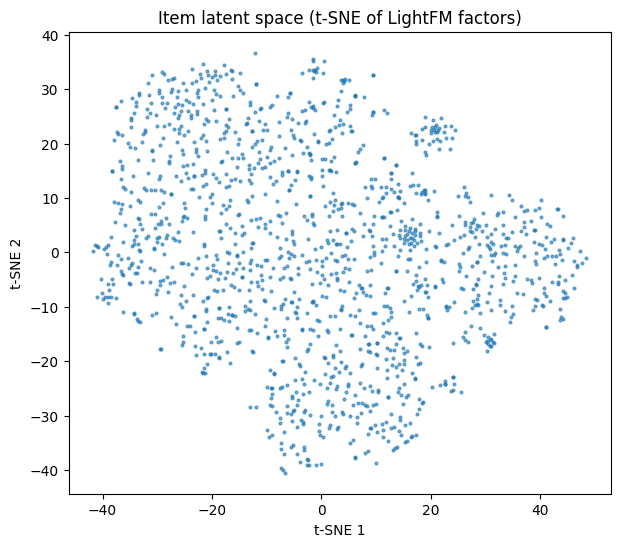

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(item_2d[:, 0], item_2d[:, 1], s=4, alpha=0.6)
plt.title("Item latent space (t‑SNE of LightFM factors)")
plt.xlabel("t‑SNE 1"); plt.ylabel("t‑SNE 2")
plt.show()